## scatter matrix

In [1]:
import pandas as pd
import sqlite3 
from pandas.plotting import scatter_matrix

conn = sqlite3.connect('../data/checking-logs.sqlite')
schema = pd.read_sql("SELECT * FROM pageviews LIMIT 10;", conn)
schema

,index,uid,datetime
0,0,admin_1,2020-04-17 12:01:08.463179
1,1,admin_1,2020-04-17 12:01:23.743946
2,2,admin_3,2020-04-17 12:17:39.287778
3,3,admin_3,2020-04-17 12:17:40.001768
4,4,admin_1,2020-04-17 12:27:30.646665
5,5,admin_1,2020-04-17 12:35:44.884757
6,6,admin_1,2020-04-17 12:35:52.735016
7,7,admin_3,2020-04-17 12:36:21.401412
8,8,admin_3,2020-04-17 12:36:22.023355
9,9,admin_1,2020-04-17 13:55:19.129243


In [2]:
checker = pd.io.sql.read_sql("""
SELECT uid, labname, timestamp 
FROM checker 
WHERE uid LIKE 'user_%' 
AND labname <> 'project1'
""", conn, parse_dates=['timestamp'])

deadlines = pd.io.sql.read_sql("""
SELECT labs as labname, deadlines 
FROM deadlines
""", conn, parse_dates=['deadlines'])

pageviews = pd.io.sql.read_sql("""
SELECT uid, count(*) as pageviews 
FROM pageviews 
WHERE uid LIKE 'user_%' 
GROUP BY uid
""", conn)

## final merge of df's

In [3]:
data = checker.merge(deadlines, on='labname', how='left')

first_commits = data.groupby(['uid', 'labname'])['timestamp'].min().reset_index()
first_commits = first_commits.merge(deadlines, on='labname', how='left')
first_commits['diff'] = (first_commits['timestamp'] - first_commits['deadlines']).dt.total_seconds() / 3600

avg_diff = first_commits.groupby('uid')['diff'].mean().reset_index().rename(columns={'diff': 'avg_diff'})
num_commits = checker.groupby('uid').size().reset_index(name='num_commits')
df = pageviews.merge(num_commits, on='uid', how='inner').merge(avg_diff, on='uid', how='inner')

In [4]:
df = df.set_index('uid')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11 entries, user_1 to user_30
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pageviews    11 non-null     int64  
 1   num_commits  11 non-null     int64  
 2   avg_diff     11 non-null     float64
dtypes: float64(1), int64(2)
memory usage: 352.0+ bytes


## visual

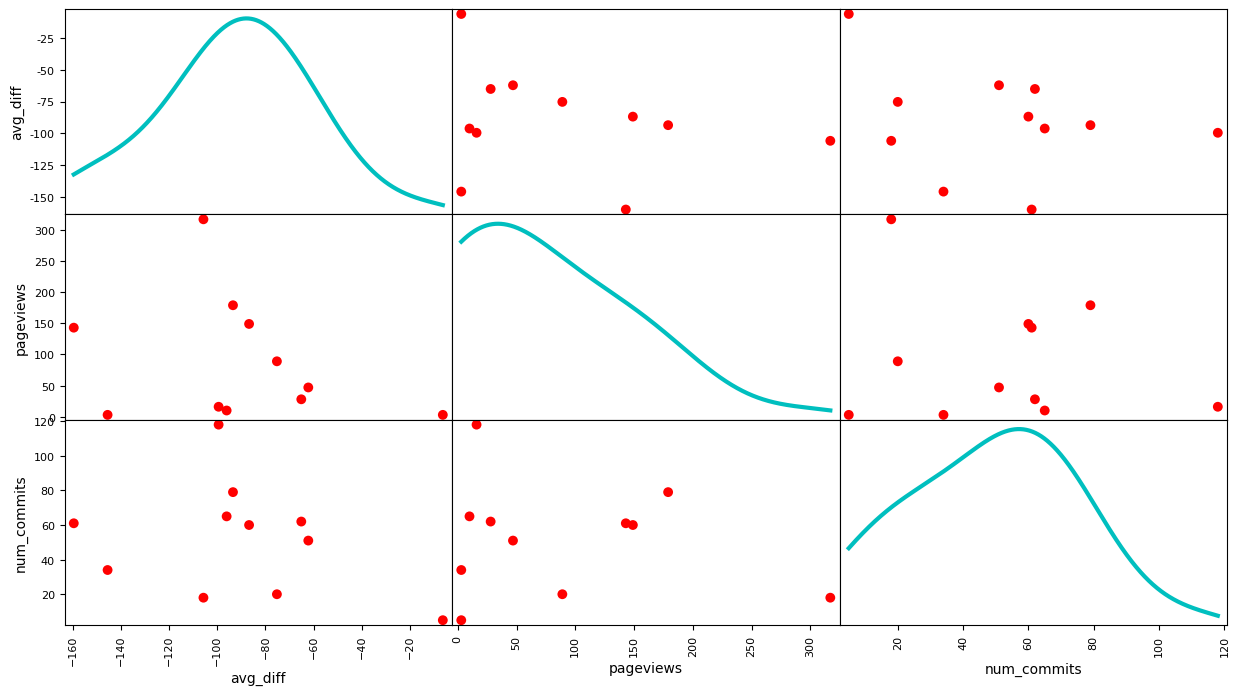

In [5]:
axes = scatter_matrix(
    df[['avg_diff', 'pageviews', 'num_commits']], 
    figsize=(15, 8),     
    diagonal='kde',
    s=200,
    color='red',
    alpha=1,
    density_kwds={'linewidth': 3, 'color': 'c'}
)
conn.close()

## Can we say that if a user has a low number of pageviews, then they likely have a low number of commits?

Answer: no

## Can we say that if a user has a low number of pageviews, then they likely have a small average difference between the first commit and the lab deadline?

Answer: no

## Can we say that there are many users with a low number of commits and a few with a high number of commits?

Answer: yes

## Can we say that there are many users with a small average difference and a few with a large average difference?

Answer: no